# HYCOM 2.2.99+CICE Currents: time series of u and v from the virtual Icechunk store

Opens `hycom_icechunks/` (`/best`: one 3-hourly series, each step from the newest 12 UTC forecast run) and
plots eastward `water_u`, northward `water_v` and speed at the surface (depth 0 m) at two points:

- **Florida Current**, Straits of Florida (25.5° N, 79.9° W = 280.1° E): strong, steady northward flow.
- **Loop Current**, eastern Gulf of Mexico (25.5° N, 86.5° W = 273.5° E): variable; eddies pass through.

Run from the `hycom/` folder in the `notebook` conda environment.

**What a read costs.** The store points at uncompressed NetCDF-3 files on TAMU-CC's server, sub-chunked to
1 time × 1 depth × 327 lat rows × 4,500 lon (2.94 MB). Any value fetches its whole chunk. Both points lie in
the same 327-row latitude band, so each chunk serves both. The full 3-hourly record would be ≈ 4,400 chunks
(≈ 13 GB), so this notebook reads:

1. the **whole record once a day** (12 UTC, the run's analysis time): ≈ 1.6 GB;
2. the **last 30 days every 3 hours**: ≈ 1.4 GB, enough to see tides and inertial oscillations.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from load_hycom import open_hycom

best = open_hycom("best", repo_path="../hycom_icechunks")
t = best.time.values
print(f"{len(t)} three-hourly steps: {str(t[0])[:13]} to {str(t[-1])[:13]} UTC; "
      f"{best.attrs['missing_steps']} steps have no file")
best[["water_u", "water_v"]]

  2026-11-19T17:31:01.208307Z  WARN icechunk::storage::object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk/src/storage/object_store.rs:92



4201 three-hourly steps: 2025-06-16T12 to 2026-11-23T12 UTC; 1983 steps have no file


<xarray.Dataset> Size: 51TB
Dimensions:                  (time: 4201, depth: 40, lat: 4251, lon: 4500)
Coordinates:
  * time                     (time) datetime64[ns] 34kB 2025-06-16T12:00:00 ....
    forecast_reference_time  (time) datetime64[ns] 34kB ...
    lead                     (time) timedelta64[ns] 34kB ...
  * depth                    (depth) float64 320B 0.0 2.0 4.0 ... 4e+03 5e+03
  * lat                      (lat) float64 34kB -80.0 -79.96 ... 89.96 90.0
  * lon                      (lon) float64 36kB 0.0 0.07996 0.16 ... 359.8 359.9
Data variables:
    water_u                  (time, depth, lat, lon) float64 26TB ...
    water_v                  (time, depth, lat, lon) float64 26TB ...
Attributes: (12/17)
    Conventions:             CF-1.8
    title:                   HYCOM 2.2.99+CICE Currents (ESPC-D V02, GLBy0.08...
    source_archive:          https://hriai01.tamucc.edu/data/MASTR_MODELS/hyc...
    source_format:           NetCDF-3 classic, uncompressed big-endian int16,...
    source_file_count:       14574
    metadata_repairs:        water_u/water_v: units m/s -> m s-1; per-file ac...
    ...                      ...
    input_data_source:       FNMOC NAVGEM, Satellite SSH, SST, SMMI, in situ ...
    reference:               https://portal.fnmoc.navy.mil/
    operational_status:      pre-operational
    distribution_statement:  Approved for public release; distribution unlimi...
    layout:                  best
    missing_steps:           1983

## The two grid cells

The grid is regular (`lat` 0.04°, `lon` 0.08°, longitude 0–360° E), so `sel(..., method="nearest")` works.

In [2]:
POINTS = {"Florida Current": (25.5, 280.1), "Loop Current": (25.5, 273.5)}
iy = {n: int(np.abs(best.lat.values - la).argmin()) for n, (la, lo) in POINTS.items()}
ix = {n: int(np.abs(best.lon.values - lo).argmin()) for n, (la, lo) in POINTS.items()}
for n in POINTS:
    print(f"{n:16s} lat[{iy[n]}] = {best.lat.values[iy[n]]:.2f} N, lon[{ix[n]}] = {best.lon.values[ix[n]]:.2f} E "
          f"({best.lon.values[ix[n]] - 360:.2f})")
assert len({j // 327 for j in iy.values()}) == 1, "points are in different latitude chunks"
names = list(POINTS)
LAT, LONS = iy[names[0]], [ix[n] for n in names]

def read(times):
    # surface u and v at both points; returns {name: Dataset with u, v, speed}
    sub = best[["water_u", "water_v"]].isel(depth=0, lat=LAT, lon=LONS).sel(time=times).load()
    out = {}
    for k, n in enumerate(names):
        p = sub.isel(lon=k)
        out[n] = p.assign(speed=np.hypot(p.water_u, p.water_v))
    return out

Florida Current  lat[2637] = 25.48 N, lon[3501] = 280.08 E (-79.92)
Loop Current     lat[2637] = 25.48 N, lon[3419] = 273.52 E (-86.48)


## 1. Whole record, once a day (12 UTC)

In [3]:
%%time
daily = t[(t.astype("datetime64[h]").astype(int) % 24) == 12]
has = best.lead.sel(time=daily).values >= np.timedelta64(0, "h")
print(f"{len(daily)} days, {has.sum()} with data -> about {2 * has.sum()} chunk reads ({2 * has.sum() * 2.943e-3:.1f} GB)")
D = read(daily)
for n, p in D.items():
    print(f"{n}: mean u {float(p.water_u.mean()):+.2f}, v {float(p.water_v.mean()):+.2f}, "
          f"speed {float(p.speed.mean()):.2f} m/s (max {float(p.speed.max()):.2f})")

526 days, 279 with data -> about 558 chunk reads (1.6 GB)


Florida Current: mean u +0.09, v +0.98, speed 0.99 m/s (max 1.70)
Loop Current: mean u +0.15, v -0.15, speed 0.58 m/s (max 1.50)
CPU times: user 4.16 s, sys: 4.72 s, total: 8.88 s
Wall time: 5.01 s


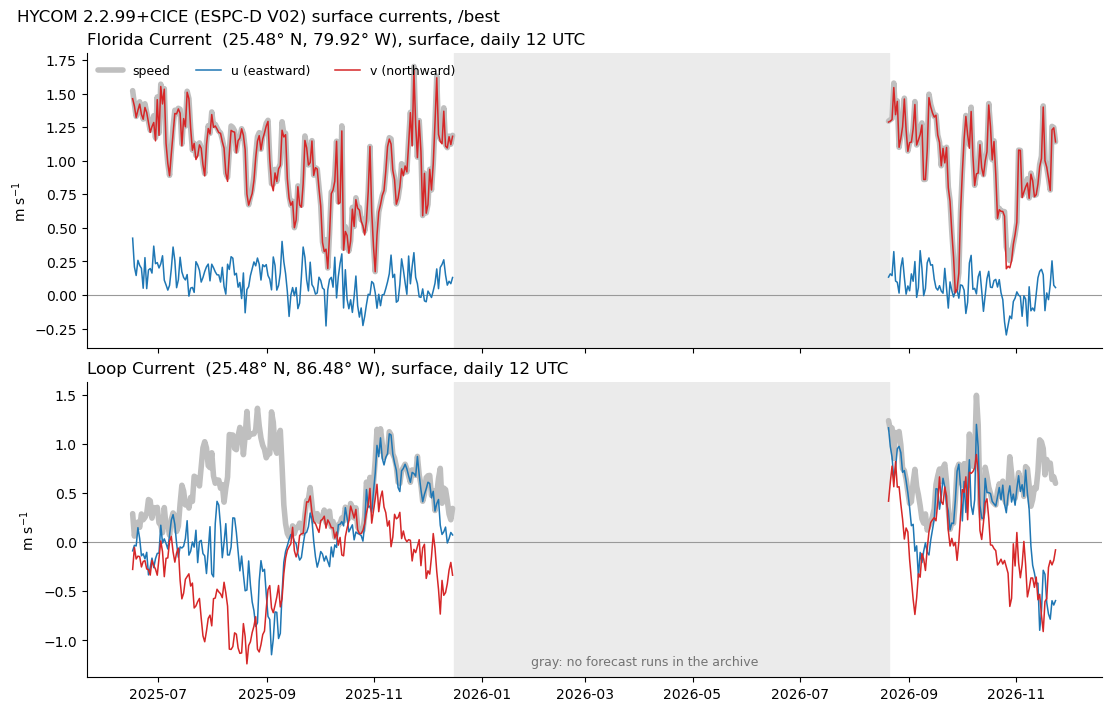

In [4]:
def gap_spans(times, ok):
    spans, start = [], None
    for ti, o in zip(times, ok):
        if not o and start is None: start = ti
        if o and start is not None: spans.append((start, ti)); start = None
    if start is not None: spans.append((start, times[-1]))
    return spans

def panel(ax, p, title, gaps=True):
    ax.axhline(0, color="0.6", lw=0.8)
    ax.plot(p.time, p.speed, color="0.75", lw=4, solid_capstyle="round", label="speed")
    ax.plot(p.time, p.water_u, color="#1f77b4", lw=1.1, label="u (eastward)")
    ax.plot(p.time, p.water_v, color="#d62728", lw=1.1, label="v (northward)")
    if gaps:
        for a, b in gap_spans(p.time.values, p.water_u.notnull().values):
            if (b - a) > np.timedelta64(3, "D"):
                ax.axvspan(a, b, color="0.92", zorder=0)
    ax.set_title(title, loc="left"); ax.set_ylabel("m s$^{-1}$")
    for s in ("top", "right"): ax.spines[s].set_visible(False)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained")
for ax, n in zip(axes, names):
    la, lo = best.lat.values[iy[n]], best.lon.values[ix[n]]
    panel(ax, D[n], f"{n}  ({la:.2f}° N, {360 - lo:.2f}° W), surface, daily 12 UTC")
axes[0].legend(loc="upper left", ncols=3, frameon=False, fontsize=9)
axes[1].text(0.55, 0.04, "gray: no forecast runs in the archive", transform=axes[1].transAxes,
             ha="center", color="0.45", fontsize=9)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.suptitle("HYCOM 2.2.99+CICE (ESPC-D V02) surface currents, /best", x=0.01, ha="left")
plt.show()

## 2. Last 30 days, every 3 hours

3-hourly output resolves the semi-diurnal/diurnal tides and inertial oscillations (period 12 h / sin(latitude),
about 28 h at 25.5° N) that daily sampling aliases. The lower panel shows which lead of which run supplies
each step: the last 8 days are forecasts from the newest run.

241 steps -> about 482 chunk reads (1.4 GB)


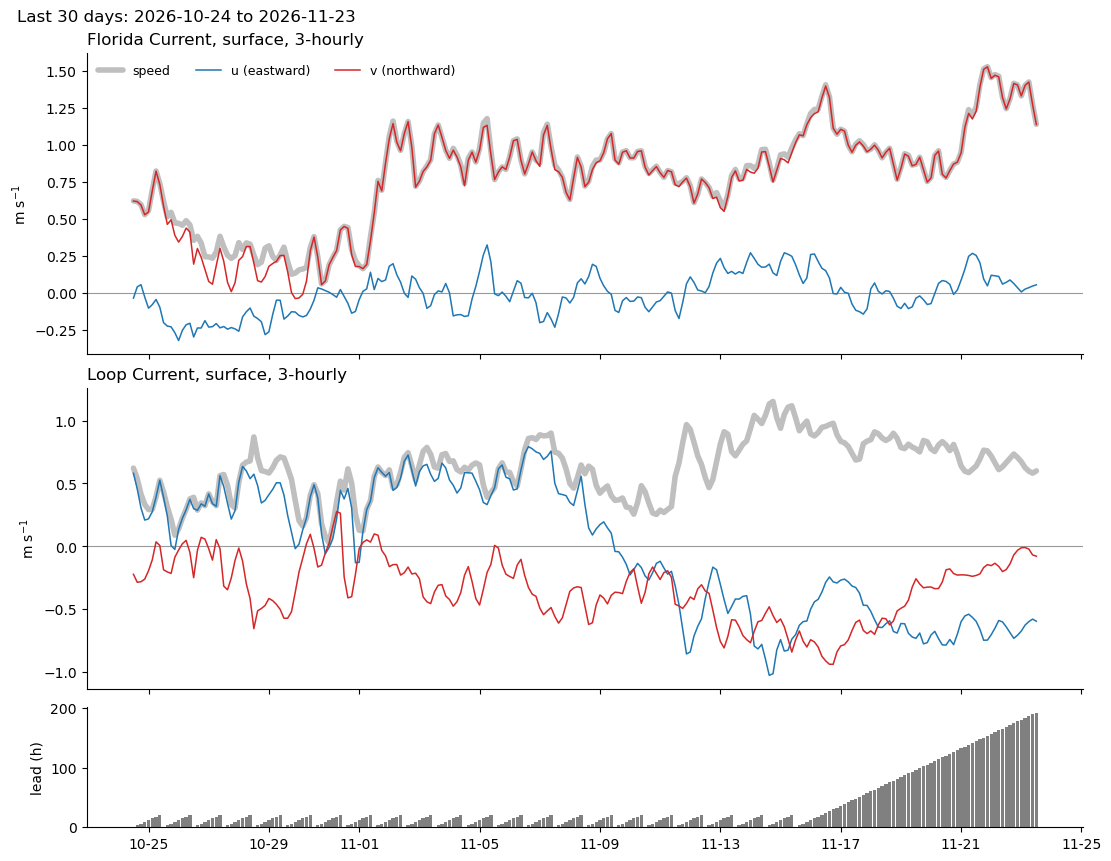

CPU times: user 3.37 s, sys: 2.73 s, total: 6.1 s
Wall time: 5.02 s


In [5]:
%%time
recent = t[t >= t[-1] - np.timedelta64(30, "D")]
print(f"{len(recent)} steps -> about {2 * len(recent)} chunk reads ({2 * len(recent) * 2.943e-3:.1f} GB)")
H = read(recent)
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, layout="constrained",
                         gridspec_kw={"height_ratios": [3, 3, 1.2]})
for ax, n in zip(axes, names):
    panel(ax, H[n], f"{n}, surface, 3-hourly", gaps=False)
axes[0].legend(loc="upper left", ncols=3, frameon=False, fontsize=9)
lead_h = (best.lead.sel(time=recent) / np.timedelta64(1, "h")).values.astype(float)
lead_h[lead_h < 0] = np.nan
axes[2].bar(recent, lead_h, width=0.11, color="0.5")
axes[2].set_ylabel("lead (h)")
for s in ("top", "right"): axes[2].spines[s].set_visible(False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
fig.suptitle(f"Last 30 days: {str(recent[0])[:10]} to {str(recent[-1])[:10]}", x=0.01, ha="left")
plt.show()

## Notes

- `water_u`/`water_v` are int16 in the source with `scale_factor` 0.001: values are quantized to 1 mm/s and
  decode to float64 (NaN over land).
- `/best` takes each 3-hourly step from the newest run that has it, so step-to-step jumps can occur where the
  supplying run changes (visible as steps in the lead panel).
- No forecast runs exist from 2025-12-09 to 2026-08-19 (gray band); `/best` is NaN there.